# Clustering

```
Textos → Vectorización (TF-IDF) → Clustering → Visualización
```

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
spanish_stopwords = stopwords.words('spanish')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Datos de texto

In [ ]:
documentos = [
    # Deportes
    "El equipo ganó el partido de fútbol en el último minuto",
    "El jugador anotó tres goles en el torneo",
    "El entrenador cambió la táctica a mitad del juego",
    "El estadio estaba lleno de aficionados emocionados",
    "El árbitro cobró un penalti muy polémico",
    "El equipo local ganó el campeonato nacional",

    # Tecnología
    "La inteligencia artificial revoluciona la industria del software",
    "El nuevo modelo de lenguaje genera texto muy convincente",
    "Python es el lenguaje más popular para ciencia de datos",
    "Las redes neuronales aprenden patrones complejos en los datos",
    "El procesador tiene ocho núcleos y mucha memoria RAM",
    "La nube permite almacenar datos de forma escalable",

    # Cocina
    "La receta lleva harina, huevos y mantequilla fresca",
    "El chef preparó una salsa con tomate y albahaca",
    "El horno debe precalentarse a 180 grados antes de hornear",
    "La pasta se cuece en agua con sal durante ocho minutos",
    "El postre de chocolate quedó esponjoso y delicioso",
    "Los ingredientes frescos hacen la diferencia en la cocina",

    # Viajes
    "El vuelo a París salió con dos horas de retraso",
    "El hotel tenía una vista increíble al mar Mediterráneo",
    "Visitamos museos y restaurantes típicos de la ciudad",
    "El pasaporte vence el próximo año y hay que renovarlo",
    "La maleta fue perdida por la aerolínea en el aeropuerto",
    "El tren de alta velocidad conecta las dos ciudades en una hora",
]

# Etiquetas reales (solo para verificar al final)
temas_reales = ['Deportes']*6 + ['Tecnología']*6 + ['Cocina']*6 + ['Viajes']*6

print(f"Total de documentos: {len(documentos)}")

Total de documentos: 24


## 3. Vectorización con TF-IDF

In [ ]:
vectorizador = TfidfVectorizer(
    max_features=100,   # usar las 100 palabras más importantes
    stop_words=spanish_stopwords     # Usar las stopwords en español
)

X = vectorizador.fit_transform(documentos)

print(f"Forma de la matriz TF-IDF: {X.shape}")
print(f"→ {X.shape[0]} documentos  x  {X.shape[1]} palabras")
print(f"\nAlgunas palabras del vocabulario (con stopwords eliminadas):")
print(vectorizador.get_feature_names_out()[:20])


Forma de la matriz TF-IDF: (24, 100)
→ 24 documentos  x  100 palabras

Algunas palabras del vocabulario (con stopwords eliminadas):
['180' 'aerolínea' 'aeropuerto' 'aficionados' 'agua' 'albahaca'
 'almacenar' 'alta' 'anotó' 'aprenden' 'artificial' 'año' 'cambió'
 'campeonato' 'chef' 'chocolate' 'ciencia' 'ciudad' 'ciudades' 'cobró']


Ahora, el `TfidfVectorizer` ha sido actualizado para usar las stopwords en español, lo que mejora la calidad de la vectorización al eliminar palabras comunes que no aportan significado semántico.

## 4. K-Means sobre texto

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
etiquetas = kmeans.fit_predict(X)

# Mostrar qué documentos quedaron en cada cluster
for cluster_id in range(5):
    print(f"\nCluster {cluster_id}:")
    for i, doc in enumerate(documentos):
        if etiquetas[i] == cluster_id:
            print(f"   • {doc}")


Cluster 0:
   • El vuelo a París salió con dos horas de retraso
   • El tren de alta velocidad conecta las dos ciudades en una hora

Cluster 1:
   • El equipo ganó el partido de fútbol en el último minuto
   • El equipo local ganó el campeonato nacional

Cluster 2:
   • El jugador anotó tres goles en el torneo
   • El entrenador cambió la táctica a mitad del juego
   • El estadio estaba lleno de aficionados emocionados
   • El árbitro cobró un penalti muy polémico
   • La inteligencia artificial revoluciona la industria del software
   • El procesador tiene ocho núcleos y mucha memoria RAM
   • La receta lleva harina, huevos y mantequilla fresca
   • El chef preparó una salsa con tomate y albahaca
   • El horno debe precalentarse a 180 grados antes de hornear
   • La pasta se cuece en agua con sal durante ocho minutos
   • El postre de chocolate quedó esponjoso y delicioso
   • Los ingredientes frescos hacen la diferencia en la cocina
   • El hotel tenía una vista increíble al mar Med

## 5. ¿Qué palabras definen cada cluster?

Podemos ver las palabras más importantes de cada grupo mirando los centroides.

In [ ]:
terminos = vectorizador.get_feature_names_out()
centroides = kmeans.cluster_centers_

print("Palabras clave por cluster:\n")
for i, centroide in enumerate(centroides):
    top_indices = centroide.argsort()[-6:][::-1]  # top 6 palabras
    palabras = [terminos[j] for j in top_indices]
    print(f"  Cluster {i}: {', '.join(palabras)}")

Palabras clave por cluster:

  Cluster 0: dos, parís, horas, conecta, hora, alta
  Cluster 1: ganó, equipo, minuto, partido, fútbol, local
  Cluster 2: ocho, museos, ciudad, polémico, penalti, cobró
  Cluster 3: datos, lenguaje, popular, python, ciencia, genera


## 6. Visualización en 2D con PCA

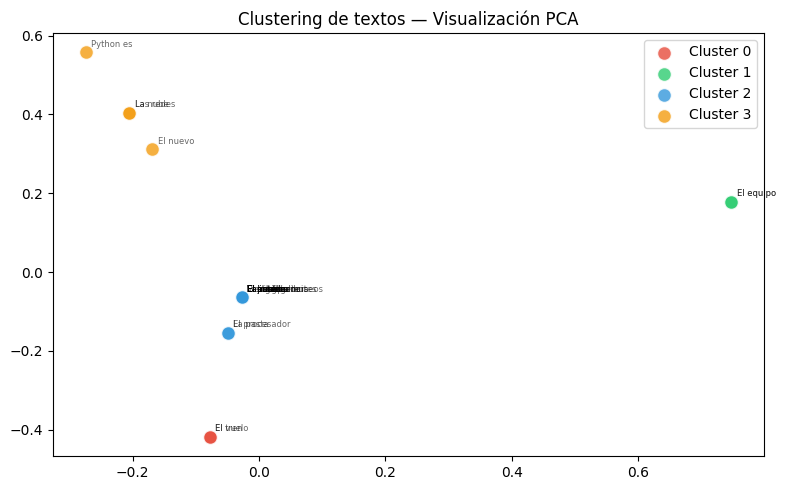

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X.toarray())

colores = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
nombres_clusters = [f'Cluster {i}' for i in range(4)]

plt.figure(figsize=(8, 5))
for i in range(4):
    mascara = etiquetas == i
    plt.scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                c=colores[i], label=nombres_clusters[i],
                s=100, alpha=0.8, edgecolors='white')

# Anotar cada punto con las primeras palabras del doc
for i, doc in enumerate(documentos):
    etiqueta_corta = doc.split()[:2]
    plt.annotate(' '.join(etiqueta_corta),
                 (X_2d[i, 0], X_2d[i, 1]),
                 fontsize=6, alpha=0.6,
                 xytext=(4, 4), textcoords='offset points')

plt.title("Clustering de textos — Visualización PCA")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Comparar con los temas reales

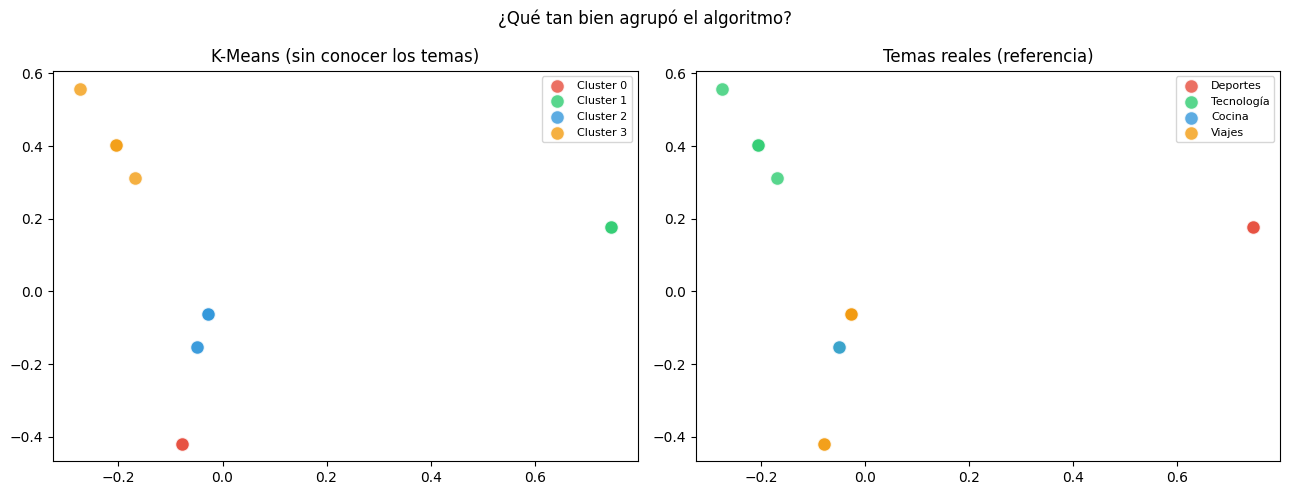

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Izquierda: clusters descubiertos por K-Means ---
for i in range(4):
    mascara = etiquetas == i
    axes[0].scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                    c=colores[i], label=f'Cluster {i}', s=100, alpha=0.8, edgecolors='white')
axes[0].set_title("K-Means (sin conocer los temas)")
axes[0].legend(fontsize=8)

# --- Derecha: temas reales ---
temas_unicos = list(dict.fromkeys(temas_reales))
for i, tema in enumerate(temas_unicos):
    mascara = [t == tema for t in temas_reales]
    axes[1].scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                    c=colores[i], label=tema, s=100, alpha=0.8, edgecolors='white')
axes[1].set_title("Temas reales (referencia)")
axes[1].legend(fontsize=8)

plt.suptitle("¿Qué tan bien agrupó el algoritmo?", fontsize=12)
plt.tight_layout()
plt.show()

## 8. Silhouette Score

El silhouette score mide qué tan bien separado está cada punto de su cluster respecto a otros clusters.

El va de -1 a 1:
- Cerca de **1** → clusters bien separados
- Cerca de **0** → clusters solapados
- Negativo → puntos mal asignados

Silhouette Score: 0.034


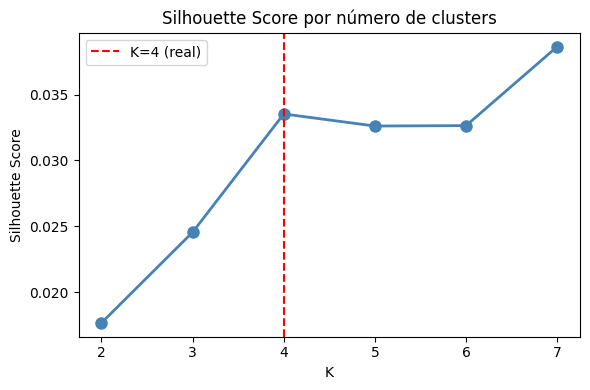

Mejor K según Silhouette: 7


In [ ]:
score = silhouette_score(X, etiquetas)
print(f"Silhouette Score: {score:.3f}")

# Probar distintos valores de K
scores = []
ks = range(2, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiq = km.fit_predict(X)
    scores.append(silhouette_score(X, etiq))

plt.figure(figsize=(6, 4))
plt.plot(ks, scores, 'o-', color='steelblue', linewidth=2, markersize=8)
plt.axvline(x=4, color='red', linestyle='--', label='K=4 (real)')
plt.title("Silhouette Score por número de clusters")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.legend()
plt.tight_layout()
plt.show()

mejor_k = ks[np.argmax(scores)]
print(f"Mejor K según Silhouette: {mejor_k}")

## 10. Agrega tus propios textos

In [ ]:
# Agrega tus propios textos aquí y cambia el número de clusters
mis_textos = [
    "El perro corre por el parque feliz",
    "El gato duerme en el sofá todo el día",
    "La bolsa de valores subió hoy tres puntos",
    "El banco central subió las tasas de interés",
    "La película ganó el premio en el festival",
    "El actor protagonizó la nueva serie de televisión",
]

N_CLUSTERS = 3   # ← cambia esto

# ─────────────────────────────────────
vec = TfidfVectorizer()
X_mis = vec.fit_transform(mis_textos)

km = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
etiq = km.fit_predict(X_mis)

for c in range(N_CLUSTERS):
    print(f"\nCluster {c}:")
    for i, t in enumerate(mis_textos):
        if etiq[i] == c:
            print(f"   • {t}")


Cluster 0:
   • El actor protagonizó la nueva serie de televisión

Cluster 1:
   • El perro corre por el parque feliz
   • El gato duerme en el sofá todo el día
   • La película ganó el premio en el festival

Cluster 2:
   • La bolsa de valores subió hoy tres puntos
   • El banco central subió las tasas de interés


## Resumen del flujo completo

```
1. Textos en español
      ↓
2. TfidfVectorizer  →  matriz numérica (docs × palabras)
      ↓
3. KMeans / Jerárquico  →  etiqueta por documento
      ↓
4. PCA (2D)  →  visualización
      ↓
5. Silhouette Score  →  evaluar calidad
```